# 현실의 데이터 29: 음성 명령 인식

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/29_speech.ipynb)

**분야**: 이미지 · 소리 · 3D &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 음성 AI · 키워드 인식 · 온디바이스

> 1초짜리 소리. 'yes' 일까 'no' 일까?

**데이터**: Speech Commands v0.02 (시험 묶음 4,890개) (약 110MB). Warden (2018), Google. 1초짜리 녹음, 단어 10개 + 침묵 + '모르는 단어' = 12종류 (CC BY 4.0). 시험 묶음만 받는다 (약 110MB).

산업 현장의 문제와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 1초짜리 녹음 하나 |
| ② 입력 X | 멜 스펙트로그램 (시간 × 주파수 에너지, dB) |
| ③ 출력 y | 12종류 (yes, no, up, … , 침묵, 모름) |
| ④ 평가지표 | 정확도 |
| ⑤ 기준선 | 가장 흔한 종류 |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [Warden (2018) Speech Commands: A Dataset for Limited-Vocabulary Speech Recognition](https://arxiv.org/abs/1804.03209)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

압축 파일 약 110MB. 처음엔 1~2분.

In [2]:
import tarfile
from scipy.io import wavfile
URL = "https://storage.googleapis.com/download.tensorflow.org/data/speech_commands_test_set_v0.02.tar.gz"
tar = tarfile.open(download(URL, "data/speech_commands_test.tar.gz"))
waves, labels, speakers = [], [], []
for member in tar.getmembers():
    if member.name.endswith(".wav"):
        rate, w = wavfile.read(io.BytesIO(tar.extractfile(member).read()))
        w = np.pad(w, (0, max(0, 16000 - len(w))))[:16000].astype(np.float32) / 32768
        waves.append(w); labels.append(member.name.split("/")[-2]); speakers.append(member.name.split("/")[-1].split("_")[0])
waves, labels, speakers = np.stack(waves), np.array(labels), np.array(speakers)
print(waves.shape, "rate", rate, "| speakers", len(set(speakers)))
print(pd.Series(labels).value_counts().to_dict())

(4890, 16000) rate 16000 | speakers 672
{'up': 425, 'yes': 419, 'left': 412, 'stop': 411, '_silence_': 408, '_unknown_': 408, 'down': 406, 'no': 405, 'go': 402, 'off': 402, 'right': 396, 'on': 396}


## 열어 보기: 파형과 멜 스펙트로그램

소리를 짧은 조각마다 주파수별 에너지로 바꾸고, 사람 귀처럼 낮은 주파수를 촘촘하게 나눈 것이 멜 스펙트로그램이다 (1주 3차시: dB 로 본다).

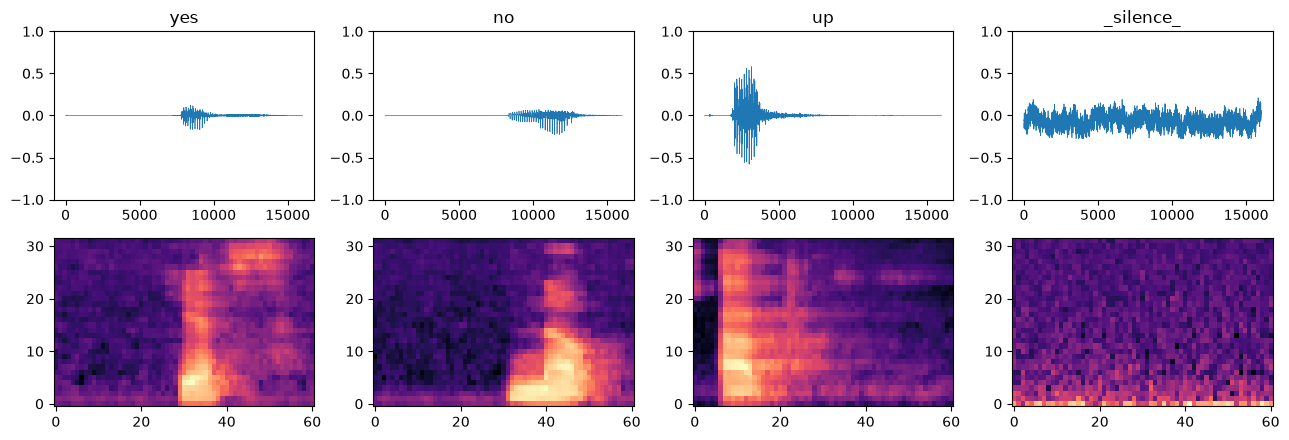

In [3]:
def mel_filterbank(n_mels=32, n_fft=512, rate=16000):
    """Triangular mel filters (n_mels x n_fft//2+1)"""
    mel = lambda f: 2595 * np.log10(1 + f / 700); inv = lambda m: 700 * (10 ** (m / 2595) - 1)
    pts = inv(np.linspace(mel(0), mel(rate / 2), n_mels + 2)); bins = np.floor((n_fft + 1) * pts / rate).astype(int)
    fb = np.zeros((n_mels, n_fft // 2 + 1))
    for i in range(1, n_mels + 1):
        l, c, r = bins[i - 1], bins[i], bins[i + 1]
        fb[i - 1, l:c] = (np.arange(l, c) - l) / max(c - l, 1); fb[i - 1, c:r] = (r - np.arange(c, r)) / max(r - c, 1)
    return fb

FB = mel_filterbank()
def log_mel(w, fb, n_fft=512, hop=256):
    """Log-mel spectrogram (n_mels x frames) of a 1-second wave"""
    frames = np.stack([w[i:i + n_fft] * np.hanning(n_fft) for i in range(0, len(w) - n_fft, hop)])
    power = np.abs(np.fft.rfft(frames, axis=1)) ** 2
    return 10 * np.log10(fb @ power.T + 1e-10)

fig, axs = plt.subplots(2, 4, figsize=(13, 4.5))
for c, word in enumerate(["yes", "no", "up", "_silence_"]):
    i = np.where(labels == word)[0][0]
    axs[0, c].plot(waves[i], lw=0.5); axs[0, c].set_title(word); axs[0, c].set_ylim(-1, 1)
    axs[1, c].imshow(log_mel(waves[i], FB), origin="lower", aspect="auto", cmap="magma")
plt.tight_layout(); plt.show()

## 문제 하나 골라 보기: 녹음 → 단어

멜 스펙트로그램을 시간 방향으로 8토막 내 평균 낸 숫자 (32 × 8 = 256개) 로 로지스틱회귀.
**나누는 방법 주의**: 한 사람이 여러 단어를 녹음했다. 같은 사람이 학습 · 시험 양쪽에 있으면 목소리를 외워서 맞힐 수 있다. **사람 단위** 로 나눈다.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def summarize(spec, n_seg=8):
    return np.concatenate([seg.mean(1) for seg in np.array_split(spec, n_seg, axis=1)])

X = np.stack([summarize(log_mel(w, FB)) for w in waves])
tr, te = next(GroupShuffleSplit(test_size=0.3, random_state=0).split(X, labels, groups=speakers))
m = make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=3000)).fit(X[tr], labels[tr])
pred = m.predict(X[te]); most = pd.Series(labels[tr]).value_counts().idxmax()
print(f"baseline (always '{most}'): accuracy {np.mean(labels[te] == most):.1%}")
print(f"logistic on log-mel summary: accuracy {np.mean(labels[te] == pred):.1%}")
print("recall per word:", pd.Series(labels[te] == pred).groupby(labels[te]).mean().round(2).to_dict())

baseline (always 'stop'): accuracy 7.8%
logistic on log-mel summary: accuracy 45.8%
recall per word: {'_silence_': 0.99, '_unknown_': 0.13, 'down': 0.35, 'go': 0.35, 'left': 0.39, 'no': 0.33, 'off': 0.59, 'on': 0.44, 'right': 0.45, 'stop': 0.46, 'up': 0.37, 'yes': 0.63}


**관찰**: 침묵은 거의 다 맞히지만 '모르는 단어' 는 열에 하나 남짓만 맞힌다. 스마트 스피커처럼 실제로 쓰려면 모르는 말을 아는 단어로 잘못 알아듣지 않는 것이 더 중요하다 (잘못 깨어남). 소리를 그대로 받는 CNN 은 90% 넘게 맞힌다.

## 다른 문제로 바꿔 보기

- **깨우는 말 (wake word)**: 하루 종일 듣다가 '헤이 ○○' 에만 반응. 한 행 = 1초 조각, 지표 = 놓친 비율 + 한 시간에 잘못 깨어난 횟수.
- 사람 단위가 아니라 무작위로 나누면 정확도가 얼마나 오를까? 해 보고, 왜 그게 거짓 점수인지 말해 보자.

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |